**import文に関して**
* oreABBR.pyでは `import ORE as ql` が実行されているが、
* ここで `import ORE as oe` とした理由は ore特有オブジェクトを強調するため
* ql と oe は 同じモジュール（ORE）を参照

In [1]:
from oreABBR import *; import ORE as oe; import oreUTIL as ou

params  = oe.Parameters()   ; params.fromFile("Input/ore.xml")
mainOBJ = oe.OREApp(params) ; mainOBJ.run()
ou.chkERR(mainOBJ)

Run time:0.06 sec, Errors:0


In [2]:
asofDT = mainOBJ.getInputs().asof() ; print('asof:',asofDT)
mainOBJ.getReportNames()

asof: August 19th, 2022


('cashflow',
 'curves',
 'dividends',
 'fixings',
 'marketdata',
 'npv',
 'pricingstats',
 'runtimes',
 'todaysmarketcalibration',
 'todaysmarketcalibration_cashflows')

In [3]:
inpOBJ = mainOBJ.getInputs()
inpOBJ.asof()

Date(19,8,2022)

In [4]:
help(mainOBJ)

Help on OREApp in module ORE object:

class OREApp(builtins.object)
 |  OREApp(*args)
 |
 |  Methods defined here:
 |
 |  __init__(self, *args)
 |      Initialize self.  See help(type(self)) for accurate signature.
 |
 |  __repr__ = _swig_repr(self) from ORE
 |
 |  closeLog(self)
 |
 |  getAnalytic(self, type)
 |
 |  getAnalyticTypes(self)
 |
 |  getCube(self, cubeName)
 |
 |  getCubeNames(self)
 |
 |  getErrors(self)
 |
 |  getInputs(self)
 |
 |  getLogger(self, name)
 |
 |  getMarketCube(self, cubeName)
 |
 |  getMarketCubeNames(self)
 |
 |  getProgressLog(self)
 |
 |  getReport(self, reportName)
 |
 |  getReportNames(self)
 |
 |  getRunTime(self)
 |
 |  getSupportedAnalyticTypes(self)
 |
 |  gitHash(self)
 |
 |  run(self, *args)
 |
 |  setupLog(self, *args)
 |
 |  version(self)
 |
 |  ----------------------------------------------------------------------
 |  Static methods defined here:
 |
 |  __swig_destroy__ = delete_OREApp(...)
 |
 |  ---------------------------------------------

**npv オブジェクト**

In [5]:
npvOBJ = mainOBJ.getReport("npv")
dfNPV = ou.rOBJxdf(npvOBJ)       ; display(dfNPV.T)

,0
TradeId,OIS-2y
TradeType,Swap
Maturity,2024-08-27
MaturityTime,2.022868
NPV,-230437.0101
NpvCurrency,JPY
NPV(Base),-230437.0101
BaseCurrency,JPY
Notional,10000000.0
NotionalCurrency,JPY


**cashflow オブジェクト**

In [6]:
cfOBJ = mainOBJ.getReport("cashflow")
dfCF  = ou.rOBJxdf(cfOBJ); print('dfCF:行列=',dfCF.shape); display(dfCF.T)
colCAL={'PresentValue':'sum'};
dfCF.groupby(['TradeId','LegNo'],as_index=False).agg(colCAL)

dfCF:行列= (4, 27)


,0,1,2,3
TradeId,OIS-2y,OIS-2y,OIS-2y,OIS-2y
Type,Swap,Swap,Swap,Swap
CashflowNo,1,2,1,2
LegNo,0,0,1,1
PayDate,2023-08-25,2024-08-27,2023-08-25,2024-08-27
FlowType,Interest,Interest,InterestProjected,InterestProjected
Amount,-120000.0,-120328.767123,1250.0,8516.474539
Currency,JPY,JPY,JPY,JPY
Coupon,0.012,0.012,0.000125,0.000849
Accrual,1.0,1.00274,1.0,1.00274


,TradeId,LegNo,PresentValue
0,OIS-2y,0,-240194.929094
1,OIS-2y,1,9757.918994


In [7]:
df = pd.DataFrame({
    'Area' : ['A', 'A', 'B', 'B'],
    'Sales': [100, 200, 300, 400],
    'Price': [10, 20, 30, 40]  }); df

,Area,Sales,Price
0,A,100,10
1,A,200,20
2,B,300,30
3,B,400,40


In [8]:
colCAL = {'Sales':'sum', 'Price':'mean'}
df.groupby('Area',as_index=False).agg(colCAL)

,Area,Sales,Price
0,A,300,15.0
1,B,700,35.0


In [9]:
df.groupby('Area').agg(colCAL)

,Sales,Price
Area,,
A,300,15.0
B,700,35.0


In [10]:
oeCF = ['TradeId','LegNo','PayDate',
          'AccrualStartDate','AccrualEndDate','Coupon','Amount', 'DiscountFactor']
dfDSP(dfCF[oeCF], fm=fmO)

,TradeId,LegNo,PayDate,AccrualStartDate,AccrualEndDate,Coupon,Amount,DiscountFactor
0,OIS-2y,0,2023-08-25,2022-08-23,2023-08-23,1.200000%,"-120,000.00",0.99987339
1,OIS-2y,0,2024-08-27,2023-08-23,2024-08-23,1.200000%,"-120,328.77",0.99901400
2,OIS-2y,1,2023-08-25,2022-08-23,2023-08-23,0.012500%,"1,250.00",0.99987339
3,OIS-2y,1,2024-08-27,2023-08-23,2024-08-23,0.084932%,"8,516.47",0.99901400


**Curves オブジェクト**

* DFの列名はTodaysMarketで定義されたもの
  * discount curveの名前は"JPY"、forward は JPY-TONAR

In [11]:
cvOBJ = mainOBJ.getReport("curves")
dfCV  = ou.rOBJxdf(cvOBJ); print('行,列:',dfCV.shape); display(dfCV[-5:])

行,列: (800, 4)


,Tenor,Date,JPY,JPY-TONAR
795,1138D,2025-09-30,0.997663,0.997663
796,1139D,2025-10-01,0.997660,0.997660
797,1140D,2025-10-02,0.997656,0.997656
798,1141D,2025-10-03,0.997653,0.997653
799,1144D,2025-10-06,0.997643,0.997643


In [12]:
dfCV.Date     = qlDT(dfCV.Date)
dfCV['tnrYR'] = dfCV.Date.map(lambda xx: yrF(dcA365,asofDT,xx))
dfCV['zeroRT']= -np.log(dfCV.JPY) / dfCV.tnrYR
dfCV.Date     = isoDT(dfCV.Date); dfCV[-5:]

,Tenor,Date,JPY,JPY-TONAR,tnrYR,zeroRT
795,1138D,2025-09-30,0.997663,0.997663,3.117808,0.000750
796,1139D,2025-10-01,0.997660,0.997660,3.120548,0.000751
797,1140D,2025-10-02,0.997656,0.997656,3.123288,0.000751
798,1141D,2025-10-03,0.997653,0.997653,3.126027,0.000752
799,1144D,2025-10-06,0.997643,0.997643,3.134247,0.000753


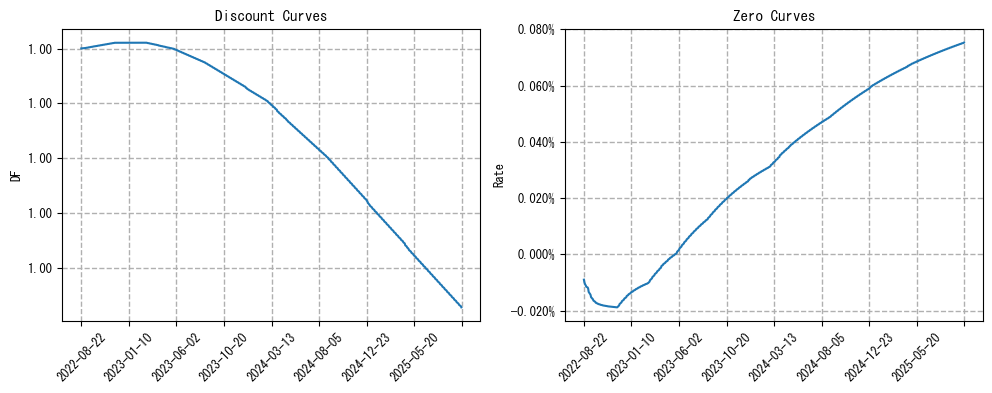

In [13]:
_,ax = plt.subplots(1,2, figsize=(10,4))
ax[0].plot(dfCV.Date,dfCV.JPY);     ax[1].plot(dfCV.Date, dfCV.zeroRT)
ax[0].set(ylabel='DF');             ax[1].set(ylabel='Rate')
ax[0].set_title('Discount Curves'); ax[1].set_title('Zero Curves')
xNum(ax);xRot(ax);yFlt(ax[0]);yPct(ax[1]);gdShow(ax)

**PlainInMemoryReport** クラスのメソッド  
-   columnType(self, i)  
-   columns(self)  
-   dataAsDate(self, *args)  
-   dataAsPeriod(self, *args)    
-   dataAsReal(self, *args)  
-   dataAsSize(self, *args)  
-   dataAsString(self, *args)  
-   header(self, i)  
-  rows(self)  

In [14]:
# Type4: Period
cvOBJ.dataAsPeriod(0)[:3]

(Period("3D"), Period("4D"), Period("5D"))

In [15]:
# Type3: Date
cvOBJ.dataAsDate(1)[:3]

(Date(22,8,2022), Date(23,8,2022), Date(24,8,2022))

In [16]:
# Type1: Real
cvOBJ.dataAsReal(2)[:3]

(1.0000007397265747, 1.0000010852067616, 1.0000014306870681)

**bound method** (メソッドを変数へ束縛) によって、以下の関数をoreUTILに作成 
* def asDA(obj): return obj.dataAsDate
* def asST(obj): return obj.dataAsString
* def asRE(obj): return obj.dataAsReal

In [17]:
dicEX = dict() ; trdID = "TradeId" ; dicEX[trdID] = [1, 2, 3]
dicEX

{'TradeId': [1, 2, 3]}